# FP-CycleGAN ➜ ResNet-18 (Full Metrics) — Auto-mount + Robust Paths
Generated 2025-11-10 06:42:01

In [5]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
# %pip -q install torchinfo scikit-learn tqdm torchvision

In [7]:

# 1) Auto-mount Google Drive (Colab)
try:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=False)
    print("Drive mounted.")
except Exception as e:
    print("Not in Colab or mount failed:", e)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive mounted.


In [9]:

# 2) Imports + robust config (detect 'My Drive' vs 'MyDrive' after mounting)
import os, random, time, math, glob
from pathlib import Path
from typing import List, Tuple, Dict
import numpy as np
from PIL import Image

import torch, torch.nn as nn, torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split

from tqdm import tqdm

try:
    from torch.cuda.amp import autocast, GradScaler
    AMP_AVAILABLE = True
except Exception:
    AMP_AVAILABLE = False

def find_first_existing(paths):
    for p in paths:
        if Path(p).exists():
            return p
    return None

DRIVE_ROOTS = ["/content/drive/My Drive", "/content/drive/MyDrive"]
DRIVE_ROOT = find_first_existing(DRIVE_ROOTS)
if DRIVE_ROOT is None:
    print("⚠ Could not find Google Drive. If in Colab, re-run the mount cell above.")
    DRIVE_ROOT = "/content/drive/My Drive"  # default

DATA_CANDIDATES = [
    f"{DRIVE_ROOT}/FPGAN/data",
    "/content/FPGAN/data",
    "./FPGAN/data",
    "./data",
]
DATA_DIR = find_first_existing(DATA_CANDIDATES)

if DATA_DIR is None:
    # List what exists to help debugging
    print("❌ Could not find your dataset in any of:", DATA_CANDIDATES)
    print("Here is what exists under your Drive root:")
    try:
        for p in Path(DRIVE_ROOT).glob("*"):
            print("  -", p)
    except Exception as e:
        print("  (cannot list drive root)", e)
    raise RuntimeError("Dataset path not found. Create 'FPGAN/data' in your Google Drive with domainA/domainB.")

class Cfg:
    DATA_DIR   = DATA_DIR
    A_DIR      = str(Path(DATA_DIR) / "domainA")
    B_DIR      = str(Path(DATA_DIR) / "domainB")
    PROJECT_DIR= str(Path(DATA_DIR).parents[1]) if len(Path(DATA_DIR).parents) >= 2 else "/content"
    OUT_DIR    = str(Path(PROJECT_DIR) / "outputs")
    CKPT_DIR   = str(Path(OUT_DIR) / "checkpoints")
    SAMPLES_DIR= str(Path(OUT_DIR) / "samples")
    LOGS_DIR   = str(Path(OUT_DIR) / "logs")
    CLS_DIR    = str(Path(OUT_DIR) / "classifier")

    IMG_SIZE = 224
    IN_CH    = 3

    SEED         = 42
    BATCH        = 8
    EPOCHS_GAN   = 30
    LR_G         = 2e-4
    LR_D         = 2e-4
    BETA1        = 0.5
    BETA2        = 0.999
    AMP          = True
    LAMBDA_CYCLE = 10.0
    LAMBDA_IDT   = 5.0
    MU_BUFFER    = 0.5
    NUM_WORKERS  = 2

    CLS_BATCH  = 32
    EPOCHS_CLS = 20
    LR_CLS     = 1e-3
    VAL_SPLIT  = 0.2

for d in [Cfg.OUT_DIR, Cfg.CKPT_DIR, Cfg.SAMPLES_DIR, Cfg.LOGS_DIR, Cfg.CLS_DIR]:
    os.makedirs(d, exist_ok=True)

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False

set_seed(Cfg.SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("DATA_DIR:", Cfg.DATA_DIR)
print("A_DIR:", Cfg.A_DIR, "exists:", Path(Cfg.A_DIR).exists())
print("B_DIR:", Cfg.B_DIR, "exists:", Path(Cfg.B_DIR).exists())


Device: cuda
DATA_DIR: /content/drive/My Drive/FPGAN/data
A_DIR: /content/drive/My Drive/FPGAN/data/domainA exists: True
B_DIR: /content/drive/My Drive/FPGAN/data/domainB exists: True


In [10]:

# 2) Imports + robust config
import os, random, time, math, glob
from pathlib import Path
from typing import List, Tuple, Dict
import numpy as np
from PIL import Image

import torch, torch.nn as nn, torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split

from tqdm import tqdm

try:
    from torch.cuda.amp import autocast, GradScaler
    AMP_AVAILABLE = True
except Exception:
    AMP_AVAILABLE = False

def find_first_existing(paths):
    for p in paths:
        if Path(p).exists():
            return p
    return None

# Prefer 'My Drive' (with space). Fall back to 'MyDrive' and local.
DRIVE_ROOTS = [
    "/content/drive/My Drive",
    "/content/drive/MyDrive",
]
DRIVE_ROOT = find_first_existing(DRIVE_ROOTS) or "/content/drive/My Drive"

# Try to detect your dataset root automatically
DATA_CANDIDATES = [
    f"{DRIVE_ROOT}/FPGAN/data",
    "/content/FPGAN/data",
    "./FPGAN/data",
    "./data",
]
DATA_DIR = find_first_existing(DATA_CANDIDATES) or f"{DRIVE_ROOT}/FPGAN/data"

class Cfg:
    DATA_DIR   = DATA_DIR
    A_DIR      = str(Path(DATA_DIR) / "domainA")
    B_DIR      = str(Path(DATA_DIR) / "domainB")
    PROJECT_DIR= str(Path(DATA_DIR).parents[1]) if len(Path(DATA_DIR).parents) >= 2 else "/content"
    OUT_DIR    = str(Path(PROJECT_DIR) / "outputs")
    CKPT_DIR   = str(Path(OUT_DIR) / "checkpoints")
    SAMPLES_DIR= str(Path(OUT_DIR) / "samples")
    LOGS_DIR   = str(Path(OUT_DIR) / "logs")
    CLS_DIR    = str(Path(OUT_DIR) / "classifier")

    IMG_SIZE = 224
    IN_CH    = 3

    SEED         = 42
    BATCH        = 8
    EPOCHS_GAN   = 30
    LR_G         = 2e-4
    LR_D         = 2e-4
    BETA1        = 0.5
    BETA2        = 0.999
    AMP          = True
    LAMBDA_CYCLE = 10.0
    LAMBDA_IDT   = 5.0
    MU_BUFFER    = 0.5
    NUM_WORKERS  = 2

    # Classifier
    CLS_BATCH  = 32
    EPOCHS_CLS = 20
    LR_CLS     = 1e-3
    VAL_SPLIT  = 0.2

for d in [Cfg.OUT_DIR, Cfg.CKPT_DIR, Cfg.SAMPLES_DIR, Cfg.LOGS_DIR, Cfg.CLS_DIR]:
    os.makedirs(d, exist_ok=True)

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False

set_seed(Cfg.SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("DATA_DIR:", Cfg.DATA_DIR)
print("A_DIR:", Cfg.A_DIR)
print("B_DIR:", Cfg.B_DIR)


Device: cuda
DATA_DIR: /content/drive/My Drive/FPGAN/data
A_DIR: /content/drive/My Drive/FPGAN/data/domainA
B_DIR: /content/drive/My Drive/FPGAN/data/domainB


In [11]:

# 3) Dataset & transforms
from torchvision import transforms

def make_transform(size):
    return transforms.Compose([
        transforms.Resize((size, size)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.5,0.5,0.5], std=[0.5,0.5,0.5])
    ])

class FolderSet(Dataset):
    IMG_EXT = (".png",".jpg",".jpeg",".bmp",".tif",".tiff")
    def __init__(self, root, transform=None):
        self.root = Path(root)
        assert self.root.exists(), f"Missing directory: {root}"
        self.transform = transform or make_transform(Cfg.IMG_SIZE)
        self.samples = []
        self.classes = []
        for d in sorted([p for p in self.root.iterdir() if p.is_dir()]):
            cls = d.name
            self.classes.append(cls)
            for f in d.rglob("*"):
                if f.suffix.lower() in self.IMG_EXT:
                    self.samples.append((str(f), cls))
        self.class_to_idx = {c:i for i,c in enumerate(self.classes)}
        print(f"[{self.root.name}] classes:", self.classes, f"(n={len(self.classes)})")
        print(f"[{self.root.name}] images:", len(self.samples))
    def __len__(self): return len(self.samples)
    def __getitem__(self, idx):
        path, cls = self.samples[idx]
        with Image.open(path) as im:
            im = im.convert("RGB")
        x = self.transform(im)
        return x, self.class_to_idx[cls], cls, path

tfm = make_transform(Cfg.IMG_SIZE)
dsA = FolderSet(Cfg.A_DIR, transform=tfm)  # domainA (Noload expected)
dsB = FolderSet(Cfg.B_DIR, transform=tfm)  # domainB (faulty classes)
dlA = DataLoader(dsA, batch_size=Cfg.BATCH, shuffle=True, num_workers=Cfg.NUM_WORKERS, drop_last=True, pin_memory=True)
dlB = DataLoader(dsB, batch_size=Cfg.BATCH, shuffle=True, num_workers=Cfg.NUM_WORKERS, drop_last=True, pin_memory=True)

print("A batches:", len(dlA), "B batches:", len(dlB))


[domainA] classes: ['Noload'] (n=1)
[domainA] images: 582
[domainB] classes: ['A&B50', 'A&C&B10', 'A&C&B30', 'A&C10', 'A&C30', 'A10', 'A30', 'A50', 'Fan', 'Rotor-0'] (n=10)
[domainB] images: 5820
A batches: 72 B batches: 727


In [12]:

# 4) Class mapping (A/B/C faults, combos, Fan, Noload, Rotor-0) + Healthy/Faulty
import re
PHASES = ("A","B","C")

def parse_class_name(name: str):
    s = name.strip(); low = s.lower()
    if low == "fan":    return {"type":"fan","phases":(),"severity":None,"raw":s}
    if low == "noload": return {"type":"noload","phases":(),"severity":None,"raw":s}
    if low.startswith("rotor"):
        m = re.search(r"rotor[-_]?(\d+)", low); sev = int(m.group(1)) if m else None
        return {"type":"rotor","phases":(), "severity":sev, "raw":s}
    m = re.match(r"^([ABC](?:&[ABC])*)(\d+)?$", s, flags=re.I)
    if m:
        phases = tuple(m.group(1).upper().split("&"))
        phases = tuple([p for p in phases if p in PHASES])
        sev = int(m.group(2)) if m.group(2) else None
        return {"type":"phase_fault","phases":phases,"severity":sev,"raw":s}
    return {"type":"unknown","phases":(),"severity":None,"raw":s}

def _sort_key(info):
    type_order = {"noload":0, "fan":1, "rotor":2, "phase_fault":3, "unknown":9}
    t = type_order.get(info["type"], 9)
    nph = len(info["phases"]); phase_tuple = info["phases"]
    sev = info["severity"] if info["severity"] is not None else 10**9
    return (t, nph, phase_tuple, sev, info["raw"].lower())

CLASS_NAMES = sorted(list(set(dsB.classes + (["Noload"] if "Noload" not in dsB.classes and "Noload" in dsA.classes else dsB.classes))), key=lambda n: _sort_key(parse_class_name(n)))
label2id = {c:i for i,c in enumerate(CLASS_NAMES)}
id2label = {i:c for c,i in label2id.items()}
print("CLASS_NAMES (ordered):", CLASS_NAMES)

HEALTHY_NAMES = {"Noload"}  # everything else -> faulty
def is_healthy(name: str) -> bool: return name in HEALTHY_NAMES


CLASS_NAMES (ordered): ['Noload', 'Fan', 'Rotor-0', 'A10', 'A30', 'A50', 'A&B50', 'A&C10', 'A&C30', 'A&C&B10', 'A&C&B30']


In [13]:

# 5) FP-CycleGAN models
class SepConv(nn.Module):
    def __init__(self, in_ch, out_ch, k=3, s=1, p=1):
        super().__init__()
        self.depth = nn.Conv2d(in_ch, in_ch, k, s, p, groups=in_ch, bias=False)
        self.point = nn.Conv2d(in_ch, out_ch, 1, 1, 0, bias=False)
        self.norm = nn.LayerNorm(out_ch); self.act = nn.GELU()
    def forward(self, x):
        x = self.depth(x); x = self.point(x)
        x = x.permute(0,2,3,1); x = self.norm(x); x = x.permute(0,3,1,2)
        return self.act(x)

class CNBlock(nn.Module):
    def __init__(self, ch, drop_path=0.0, layer_scale=1.0):
        super().__init__()
        self.dw = nn.Conv2d(ch, ch, 7,1,3, groups=ch)
        self.norm = nn.LayerNorm(ch)
        self.pw1 = nn.Conv2d(ch, 4*ch, 1); self.act = nn.GELU(); self.pw2 = nn.Conv2d(4*ch, ch, 1)
        self.gamma = nn.Parameter(layer_scale * torch.ones((ch)), requires_grad=True)
        self.drop_path = nn.Dropout(drop_path) if drop_path>0 else nn.Identity()
    def forward(self, x):
        s=x; x=self.dw(x); x=x.permute(0,2,3,1); x=self.norm(x); x=x.permute(0,3,1,2)
        x=self.pw1(x); x=self.act(x); x=self.pw2(x); x=x*self.gamma.view(1,-1,1,1); x=self.drop_path(x); return x+s

def upsample_bicubic(x, scale_factor=2): return F.interpolate(x, scale_factor=scale_factor, mode='bicubic', align_corners=False)

class UpBlock(nn.Module):
    def __init__(self, in_ch, skip_ch, out_ch):
        super().__init__(); self.conv1 = SepConv(in_ch+skip_ch, out_ch); self.conv2 = SepConv(out_ch, out_ch)
    def forward(self, x, skip): x=upsample_bicubic(x,2); x=torch.cat([x,skip],1); x=self.conv1(x); x=self.conv2(x); return x

class GeneratorUNet(nn.Module):
    def __init__(self, in_ch=3, out_ch=3, dims=(96,192,384,768)):
        super().__init__()
        self.stem = nn.Conv2d(in_ch, dims[0], 4,4,0)
        self.down1 = nn.Sequential(CNBlock(dims[0]), CNBlock(dims[0]), nn.Conv2d(dims[0], dims[1], 2,2))
        self.down2 = nn.Sequential(CNBlock(dims[1]), CNBlock(dims[1]), nn.Conv2d(dims[1], dims[2], 2,2))
        self.down3 = nn.Sequential(CNBlock(dims[2]), nn.Conv2d(dims[2], dims[3], 2,2))
        self.bot   = nn.Sequential(CNBlock(dims[3]), CNBlock(dims[3]), CNBlock(dims[3]))
        self.up1   = UpBlock(dims[3], dims[2], dims[2])
        self.up2   = UpBlock(dims[2], dims[1], dims[1])
        self.up3   = UpBlock(dims[1], dims[0], dims[0])
        self.to_rgb= nn.Sequential(nn.ConvTranspose2d(dims[0], out_ch, 4,4,0), nn.Tanh())
    def forward(self, x):
        s0=self.stem(x); s1=self.down1(s0); s2=self.down2(s1); s3=self.down3(s2)
        b=self.bot(s3); u1=self.up1(b,s2); u2=self.up2(u1,s1); u3=self.up3(u2,s0); return self.to_rgb(u3)

class PatchDiscriminator(nn.Module):
    def __init__(self, ch=64, in_ch=3):
        super().__init__()
        def C(in_c, out_c, k=4, s=2, p=1, norm=True):
            seq=[nn.Conv2d(in_c,out_c,k,s,p)]
            if norm: seq += [nn.InstanceNorm2d(out_c)]
            seq += [nn.LeakyReLU(0.2, inplace=True)]; return nn.Sequential(*seq)
        self.net = nn.Sequential(C(in_ch,ch, norm=False), C(ch,ch*2), C(ch*2,ch*4), C(ch*4,ch*8, s=1), nn.Conv2d(ch*8,1,4,1,1))
    def forward(self, x): return self.net(x)

class D_AB_Classifier(nn.Module):
    def __init__(self, in_ch=3, base=64):
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv2d(in_ch, base, 4,2,1), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(base, base*2, 4,2,1), nn.BatchNorm2d(base*2), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(base*2, base*4, 4,2,1), nn.BatchNorm2d(base*4), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(base*4, base*8, 4,2,1), nn.BatchNorm2d(base*8), nn.LeakyReLU(0.2, inplace=True),
        )
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(base*8, 2))
    def forward(self, x): return self.head(self.body(x))


In [14]:

# 6) Instantiate + train utils
G_AB = GeneratorUNet(Cfg.IN_CH, Cfg.IN_CH).to(device)
G_BA = GeneratorUNet(Cfg.IN_CH, Cfg.IN_CH).to(device)
D_A  = PatchDiscriminator(in_ch=Cfg.IN_CH).to(device)
D_B  = PatchDiscriminator(in_ch=Cfg.IN_CH).to(device)
D_AB = D_AB_Classifier(in_ch=Cfg.IN_CH).to(device)

opt_G  = optim.Adam(list(G_AB.parameters())+list(G_BA.parameters()), lr=Cfg.LR_G, betas=(Cfg.BETA1, Cfg.BETA2))
opt_DA = optim.Adam(D_A.parameters(), lr=Cfg.LR_D, betas=(Cfg.BETA1, Cfg.BETA2))
opt_DB = optim.Adam(D_B.parameters(), lr=Cfg.LR_D, betas=(Cfg.BETA1, Cfg.BETA2))
opt_DAB= optim.Adam(D_AB.parameters(), lr=Cfg.LR_D, betas=(Cfg.BETA1, Cfg.BETA2))

mse = nn.MSELoss(); l1 = nn.L1Loss(); ce = nn.CrossEntropyLoss()

class ImageBuffer:
    def __init__(self, max_size=50): self.max_size=max_size; self.data=[]
    def push_and_pop(self, tensors):
        out=[]
        for t in tensors:
            t=t.detach()
            if len(self.data) < self.max_size:
                self.data.append(t); out.append(t)
            else:
                if random.random()>0.5:
                    idx=random.randint(0,self.max_size-1); tmp=self.data[idx].clone(); self.data[idx]=t; out.append(tmp)
                else: out.append(t)
        return torch.stack(out,0)

buf_A = ImageBuffer(50); buf_B = ImageBuffer(50)
scaler = GradScaler(enabled=Cfg.AMP and AMP_AVAILABLE)

class TrainMonitor:
    def __init__(self): self.losses={}
    def log(self,k,v): self.losses.setdefault(k,[]).append(float(v))
monitor = TrainMonitor()

def denorm(t): return (t*0.5+0.5).clamp(0,1)
def save_grid(path, *tensors, ncols=4):
    from torchvision.utils import save_image
    arrs=[denorm(x.detach().cpu()) for x in tensors]
    x=torch.cat(arrs,0); B,C,H,W=x.size(0),x.size(1),x.size(2),x.size(3)
    nrows=(B+ncols-1)//ncols; grid=torch.ones(C,nrows*H,ncols*W)
    for i in range(B):
        r,c=divmod(i,ncols); grid[:, r*H:(r+1)*H, c*W:(c+1)*W]=x[i]
    Path(path).parent.mkdir(parents=True, exist_ok=True); save_image(grid, path)

import matplotlib.pyplot as plt
def plot_loss_curves(monitor, keys=("G_total","D_A","D_B","D_AB"), savepath=None):
    fig=plt.figure()
    for k in keys:
        if k in monitor.losses: plt.plot(monitor.losses[k], label=k)
    plt.legend(); plt.xlabel("Iterations"); plt.ylabel("Loss"); plt.title("Loss Curves")
    if savepath: Path(savepath).parent.mkdir(parents=True, exist_ok=True); plt.savefig(savepath, dpi=200, bbox_inches='tight')
    plt.show()

def train_epoch(epoch, dlA, dlB):
    G_AB.train(); G_BA.train(); D_A.train(); D_B.train(); D_AB.train()
    iters=min(len(dlA),len(dlB)); loopA=iter(dlA); loopB=iter(dlB)
    with torch.no_grad():
        dummy=torch.randn(Cfg.BATCH, Cfg.IN_CH, Cfg.IMG_SIZE, Cfg.IMG_SIZE, device=device); shape=D_A(dummy).shape
    valid=torch.ones(shape, device=device); fakev=torch.zeros(shape, device=device)
    for it in tqdm(range(iters), desc=f"Epoch {epoch}"):
        realA,_,_,_ = next(loopA); realB,_,_,_ = next(loopB)
        realA=realA.to(device,non_blocking=True); realB=realB.to(device,non_blocking=True)

        opt_G.zero_grad(set_to_none=True)
        with autocast(enabled=Cfg.AMP and AMP_AVAILABLE):
            fakeB=G_AB(realA); fakeA=G_BA(realB)
            recA=G_BA(fakeB);  recB=G_AB(fakeA)
            idtA=G_BA(realA);  idtB=G_AB(realB)
            loss_GAN_AB=mse(D_B(fakeB), valid); loss_GAN_BA=mse(D_A(fakeA), valid)
            loss_cycle=l1(recA,realA)+l1(recB,realB); loss_idt=l1(idtA,realA)+l1(idtB,realB)
            bsz=realA.size(0); n_real=int(Cfg.MU_BUFFER*bsz)
            idxA=torch.randperm(bsz, device=device)[:n_real]; idxB=torch.randperm(bsz, device=device)[:n_real]
            newA=torch.cat([realA[idxA], buf_A.push_and_pop(fakeA.detach().cpu())[:bsz-n_real].to(device)],0)
            newB=torch.cat([realB[idxB], buf_B.push_and_pop(fakeB.detach().cpu())[:bsz-n_real].to(device)],0)
            logits_A=D_AB(newA); logits_B=D_AB(newB)
            loss_class=ce(logits_A, torch.zeros(logits_A.size(0), dtype=torch.long, device=device)) +                        ce(logits_B, torch.ones (logits_B.size(0), dtype=torch.long, device=device))
            loss_G=loss_GAN_AB+loss_GAN_BA+Cfg.LAMBDA_CYCLE*loss_cycle+Cfg.LAMBDA_IDT*loss_idt+loss_class
        scaler.scale(loss_G).backward(); scaler.step(opt_G); scaler.update(); monitor.log("G_total", loss_G.item())

        opt_DA.zero_grad(set_to_none=True)
        with autocast(enabled=Cfg.AMP and AMP_AVAILABLE):
            loss_DA=0.5*(mse(D_A(realA), valid)+mse(D_A(fakeA.detach()), fakev))
        scaler.scale(loss_DA).backward(); scaler.step(opt_DA); scaler.update(); monitor.log("D_A", loss_DA.item())

        opt_DB.zero_grad(set_to_none=True)
        with autocast(enabled=Cfg.AMP and AMP_AVAILABLE):
            loss_DB=0.5*(mse(D_B(realB), valid)+mse(D_B(fakeB.detach()), fakev))
        scaler.scale(loss_DB).backward(); scaler.step(opt_DB); scaler.update(); monitor.log("D_B", loss_DB.item())

        opt_DAB.zero_grad(set_to_none=True)
        with autocast(enabled=Cfg.AMP and AMP_AVAILABLE):
            logits_A=D_AB(newA.detach()); logits_B=D_AB(newB.detach())
            loss_DAB=ce(logits_A, torch.zeros(logits_A.size(0), dtype=torch.long, device=device)) +                      ce(logits_B, torch.ones (logits_B.size(0), dtype=torch.long, device=device))
        scaler.scale(loss_DAB).backward(); scaler.step(opt_DAB); scaler.update(); monitor.log("D_AB", loss_DAB.item())

        if it % 100 == 0:
            save_grid(str(Path(Cfg.SAMPLES_DIR)/f"e{epoch:03d}_i{it:05d}.png"), realA[:4], fakeB[:4], recA[:4], realB[:4], fakeA[:4], recB[:4])

def save_ckpt(epoch):
    payload={"epoch":epoch,"G_AB":G_AB.state_dict(),"G_BA":G_BA.state_dict(),"D_A":D_A.state_dict(),
             "D_B":D_B.state_dict(),"D_AB":D_AB.state_dict(),"opt_G":opt_G.state_dict(),
             "opt_DA":opt_DA.state_dict(),"opt_DB":opt_DB.state_dict(),"opt_DAB":opt_DAB.state_dict()}
    p=str(Path(Cfg.CKPT_DIR)/f"fpgan_e{epoch:03d}.pt"); torch.save(payload,p); print("Saved:",p)


/tmp/ipykernel_3034/112552208.py:30: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler(enabled=Cfg.AMP and AMP_AVAILABLE)


Epoch 1:   0%|          | 0/72 [00:00<?, ?it/s]/tmp/ipykernel_3034/112552208.py:67: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=Cfg.AMP and AMP_AVAILABLE):
/tmp/ipykernel_3034/112552208.py:83: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=Cfg.AMP and AMP_AVAILABLE):
/tmp/ipykernel_3034/112552208.py:88: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=Cfg.AMP and AMP_AVAILABLE):
/tmp/ipykernel_3034/112552208.py:93: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=Cfg.AMP and AMP_AVAILABLE):
Epoch 5: 100%|██████████| 72/72 [02:34<00:00,  2.14s/it]


Saved: /content/drive/My Drive/outputs/checkpoints/fpgan_e005.pt


Epoch 10: 100%|██████████| 72/72 [01:22<00:00,  1.15s/it]


Saved: /content/drive/My Drive/outputs/checkpoints/fpgan_e010.pt


Epoch 15: 100%|██████████| 72/72 [00:59<00:00,  1.21it/s]


Saved: /content/drive/My Drive/outputs/checkpoints/fpgan_e015.pt


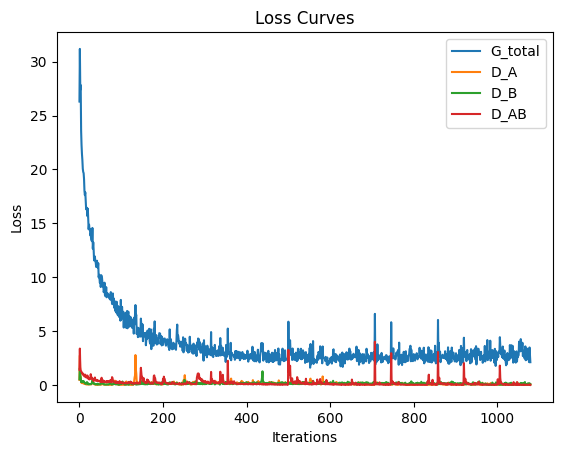

GAN training done.


In [15]:
# 7) Train GAN (Configured for 15 epochs)
EPOCHS_TO_RUN = 15

for epoch in range(1, EPOCHS_TO_RUN + 1):
    train_epoch(epoch, dlA, dlB)
    if epoch % 5 == 0 or epoch == EPOCHS_TO_RUN:
        save_ckpt(epoch)

plot_loss_curves(monitor, savepath=str(Path(Cfg.LOGS_DIR)/"loss_curves_gan.png"))
print("GAN training done.")

In [16]:

# 8) ResNet-18 classifier (+ utilities)
from torchvision import models
def adapt_classifier(model: nn.Module, n_classes: int):
    if hasattr(model,'fc') and isinstance(model.fc, nn.Linear):
        model.fc = nn.Linear(model.fc.in_features, n_classes); print("Replaced .fc ->", n_classes)
    else:
        last_linear=None; last_name=None
        for name,m in model.named_modules():
            if isinstance(m, nn.Linear): last_linear, last_name=m, name
        if last_linear is not None:
            parent=model; parts=last_name.split('.')[:-1]; leaf=last_name.split('.')[-1]
            for p in parts: parent=getattr(parent,p); setattr(parent, leaf, nn.Linear(last_linear.in_features, n_classes))
            print(f"Replaced {last_name} -> {n_classes}")
    return model

def probe_io(model, input_shape=(3, Cfg.IMG_SIZE, Cfg.IMG_SIZE)):
    x=torch.randn(1,*input_shape).to(device); model=model.to(device).eval()
    with torch.no_grad(): y=model(x)
    print("Input:",tuple(x.shape),"-> Output:",tuple(y.shape) if hasattr(y,'shape') else type(y)); return x,y

def model_summary(model, input_size=(3, Cfg.IMG_SIZE, Cfg.IMG_SIZE)):
    try:
        from torchinfo import summary
        return summary(model.to(device), input_size=(1,*input_size))
    except Exception as e:
        print("torchinfo not available. Params:", sum(p.numel() for p in model.parameters()))

def save_hparam_table(table_path, **hparams):
    import pandas as pd
    rows=[{"Hyperparameter":k,"Value":v} for k,v in hparams.items()]
    df=pd.DataFrame(rows); Path(table_path).parent.mkdir(parents=True, exist_ok=True); df.to_csv(table_path,index=False); print("Saved:",table_path); return df

table2 = save_hparam_table(str(Path(Cfg.LOGS_DIR)/"table2_hparams.csv"),
    img_size=Cfg.IMG_SIZE, batch_gan=Cfg.BATCH, epochs_gan=Cfg.EPOCHS_GAN, lr_g=Cfg.LR_G, lr_d=Cfg.LR_D,
    lambda_cycle=Cfg.LAMBDA_CYCLE, lambda_idt=Cfg.LAMBDA_IDT, mu_buffer=Cfg.MU_BUFFER, amp=Cfg.AMP,
    classes="|".join(CLASS_NAMES), n_classes=len(CLASS_NAMES))


Saved: /content/drive/My Drive/outputs/logs/table2_hparams.csv


In [18]:

# 9) Build classifier dataset (domainB + optional Noload from A)
class ClassifierFolderSet(Dataset):
    def __init__(self, roots: List[Path], transform=None):
        self.transform=transform or make_transform(Cfg.IMG_SIZE)
        self.samples=[]; kept=set(CLASS_NAMES)
        for root in roots:
            root=Path(root)
            if not root.exists(): continue
            for d in sorted([p for p in root.iterdir() if p.is_dir()]):
                cls=d.name
                if cls not in kept: continue
                for f in d.rglob("*"):
                    if f.suffix.lower() in FolderSet.IMG_EXT: self.samples.append((str(f), cls))
        random.shuffle(self.samples); self.label2id={c:i for i,c in enumerate(CLASS_NAMES)}
        print("Classifier samples:", len(self.samples), "classes:", CLASS_NAMES)
    def __len__(self): return len(self.samples)
    def __getitem__(self, idx):
        path, cls = self.samples[idx]; im=Image.open(path).convert("RGB"); x=self.transform(im); y=self.label2id[cls]; return x,y,cls,path

cls_ds = ClassifierFolderSet([Path(Cfg.B_DIR), Path(Cfg.A_DIR)], transform=make_transform(Cfg.IMG_SIZE))
val_len = max(1, int(len(cls_ds)*Cfg.VAL_SPLIT)); train_len = max(1, len(cls_ds)-val_len)
cls_train, cls_val = random_split(cls_ds, [train_len, val_len], generator=torch.Generator().manual_seed(Cfg.SEED))

dl_train = DataLoader(cls_train, batch_size=Cfg.CLS_BATCH, shuffle=True,  num_workers=Cfg.NUM_WORKERS, pin_memory=True)
dl_val   = DataLoader(cls_val,   batch_size=Cfg.CLS_BATCH, shuffle=False, num_workers=Cfg.NUM_WORKERS, pin_memory=True)

print("Classifier train batches:", len(dl_train), "val batches:", len(dl_val))


Classifier samples: 6402 classes: ['Noload', 'Fan', 'Rotor-0', 'A10', 'A30', 'A50', 'A&B50', 'A&C10', 'A&C30', 'A&C&B10', 'A&C&B30']
Classifier train batches: 161 val batches: 40


In [21]:

# 10) Train ResNet-18
clf = models.resnet18(weights=None)
clf = adapt_classifier(clf, n_classes=len(CLASS_NAMES))
probe_io(clf); model_summary(clf)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(clf.parameters(), lr=Cfg.LR_CLS)
best_val_acc, best_path = 0.0, str(Path(Cfg.CLS_DIR)/"best_resnet18.pt")

def evaluate(model, loader):
    model.eval(); correct=0; total=0; losses=[]
    with torch.no_grad():
        for xb, yb, cls, p in loader:
            xb=xb.to(device); yb=yb.to(device)
            out=model(xb); loss=criterion(out,yb); pred=out.argmax(-1)
            correct += (pred==yb).sum().item(); total += yb.numel(); losses.append(loss.item())
    return correct/max(total,1), float(np.mean(losses)) if losses else 0.0

clf = clf.to(device)
for ep in range(1, Cfg.EPOCHS_CLS+1):
    clf.train(); running=0.0; n=0
    for xb, yb, cls, p in dl_train:
        xb=xb.to(device); yb=yb.to(device)
        optimizer.zero_grad(set_to_none=True)
        out=clf(xb); loss=criterion(out,yb); loss.backward(); optimizer.step()
        running += loss.item()*yb.size(0); n += yb.size(0)
    tr_loss = running/max(n,1)
    val_acc, val_loss = evaluate(clf, dl_val)
    print(f"[{ep:03d}] train_loss={tr_loss:.4f}  val_loss={val_loss:.4f}  val_acc={val_acc:.4f}")
    if val_acc > best_val_acc:
        best_val_acc = val_acc; torch.save({"model": clf.state_dict(), "classes": CLASS_NAMES}, best_path); print("  ↳ saved best:", best_path)
print("Classifier training done. Best val acc:", best_val_acc)


Replaced .fc -> 11
Input: (1, 3, 224, 224) -> Output: (1, 11)
torchinfo not available. Params: 11182155
[001] train_loss=0.6503  val_loss=0.6892  val_acc=0.7461
  ↳ saved best: /content/drive/My Drive/outputs/classifier/best_resnet18.pt
[002] train_loss=0.5103  val_loss=0.5263  val_acc=0.7352
[003] train_loss=0.3673  val_loss=1.8507  val_acc=0.5836
[004] train_loss=0.3532  val_loss=0.7505  val_acc=0.7156
[005] train_loss=0.3058  val_loss=0.1973  val_acc=0.9203
  ↳ saved best: /content/drive/My Drive/outputs/classifier/best_resnet18.pt
[006] train_loss=0.2472  val_loss=0.2617  val_acc=0.8609
[007] train_loss=0.2204  val_loss=3.4112  val_acc=0.5437
[008] train_loss=0.1894  val_loss=0.3032  val_acc=0.8703
[009] train_loss=0.2360  val_loss=0.2524  val_acc=0.8969
[010] train_loss=0.1983  val_loss=0.2187  val_acc=0.8859
[011] train_loss=0.1767  val_loss=1.4348  val_acc=0.6805
[012] train_loss=0.1599  val_loss=0.2993  val_acc=0.8609
[013] train_loss=0.1516  val_loss=0.2630  val_acc=0.8875
[01

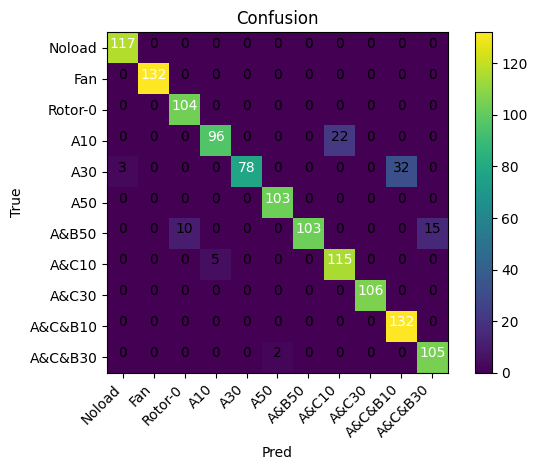

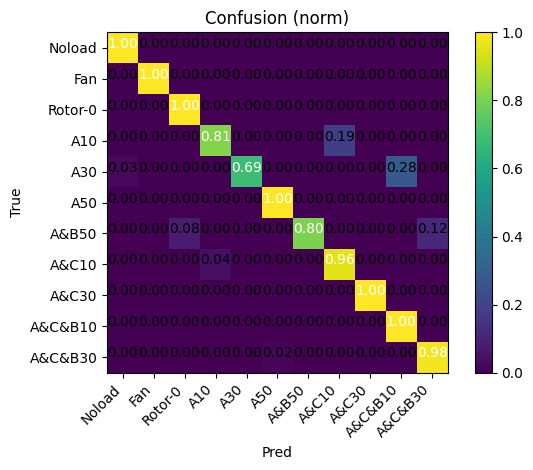

      class  precision    recall        f1  support
0    Noload   0.975000  1.000000  0.987342      117
1       Fan   1.000000  1.000000  1.000000      132
2   Rotor-0   0.912281  1.000000  0.954128      104
3       A10   0.950495  0.813559  0.876712      118
4       A30   1.000000  0.690265  0.816754      113
5       A50   0.980952  1.000000  0.990385      103
6     A&B50   1.000000  0.804688  0.891775      128
7     A&C10   0.839416  0.958333  0.894942      120
8     A&C30   1.000000  1.000000  1.000000      106
9   A&C&B10   0.804878  1.000000  0.891892      132
10  A&C&B30   0.875000  0.981308  0.925110      107
Macro: {'precision': 0.9398202035805787, 'recall': 0.9316503684825318, 'f1': 0.9299126939489817, 'support': 1280}
Micro: {'precision': 0.93046875, 'recall': 0.93046875, 'f1': 0.93046875, 'support': 1280}
Weighted: {'precision': 0.9388652605534837, 'recall': 0.93046875, 'f1': 0.9287186759087384, 'support': 1280}


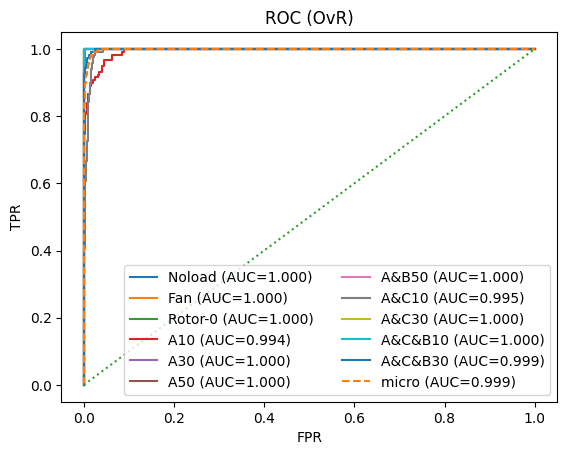

Binary confusion
 [[ 117    0]
 [   3 1160]]


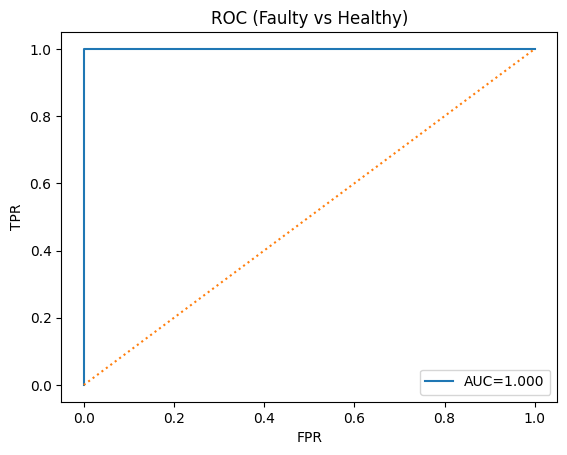

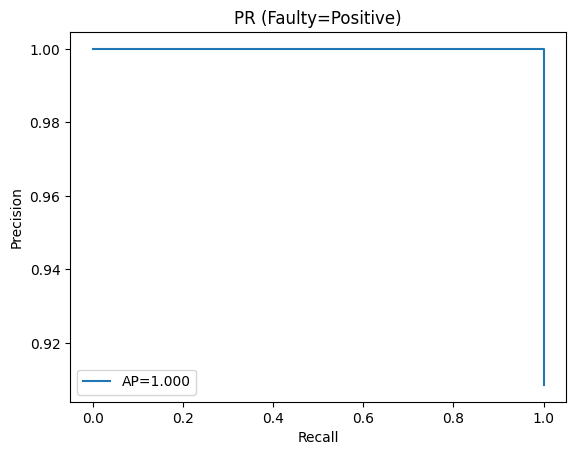

In [22]:
# 11) Metrics & plots (confusion, PRF1, ROC OvR + Binary Healthy/Faulty) — ROBUST
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix, classification_report, roc_curve, auc,
    precision_recall_fscore_support, average_precision_score, precision_recall_curve
)
import torch

# ---- Try to ensure `clf` exists (load best checkpoint if not in memory) ----
if "clf" not in globals():
    from torchvision import models
    clf = models.resnet18(weights=None)
    # adapt head
    if hasattr(clf, "fc") and isinstance(clf.fc, torch.nn.Linear):
        clf.fc = torch.nn.Linear(clf.fc.in_features, len(CLASS_NAMES))
    else:
        # last-resort head replacement
        last = None; last_name = None
        for nm, m in clf.named_modules():
            if isinstance(m, torch.nn.Linear): last, last_name = m, nm
        if last is not None:
            parent = clf; parts = last_name.split('.')[:-1]; leaf = last_name.split('.')[-1]
            for p in parts: parent = getattr(parent, p)
            setattr(parent, leaf, torch.nn.Linear(last.in_features, len(CLASS_NAMES)))

    # 1) try project best
    best_p = Path(Cfg.CLS_DIR) / "best_resnet18.pt"
    loaded = False
    if best_p.exists():
        ckpt = torch.load(str(best_p), map_location=device)
        clf.load_state_dict(ckpt["model"]); loaded = True
        print("Loaded classifier from:", best_p)
    # 2) fallback to uploaded notebook path (if you ran here)
    if not loaded:
        alt = Path("/mnt/data/best_resnet18.pt")
        if alt.exists():
            ckpt = torch.load(str(alt), map_location=device)
            clf.load_state_dict(ckpt["model"]); loaded = True
            print("Loaded classifier from:", alt)
    if not loaded:
        print("⚠ Could not auto-load a saved classifier; proceeding with current (untrained) weights.")

clf = clf.to(device).eval()

def collect_predictions(model, loader, device=None):
    device = device or ("cuda" if torch.cuda.is_available() else "cpu")
    model = model.to(device).eval()
    ys_true, ys_pred, ys_score = [], [], []
    with torch.no_grad():
        for xb, yb, cls, p in loader:
            xb = xb.to(device)
            out = model(xb)
            probs = torch.softmax(out, dim=-1)
            ys_true.append(yb.cpu().numpy())
            ys_pred.append(probs.argmax(-1).cpu().numpy())
            ys_score.append(probs.cpu().numpy())
    y_true = np.concatenate(ys_true, 0)
    y_pred = np.concatenate(ys_pred, 0)
    y_score = np.concatenate(ys_score, 0)
    return y_true, y_pred, y_score

def plot_confusion(y_true, y_pred, class_names=None, normalize=False, title=None, savepath=None):
    cm = confusion_matrix(y_true, y_pred)
    if normalize:
        cm = cm.astype('float') / (cm.sum(axis=1, keepdims=True) + 1e-12)
    fig = plt.figure()
    plt.imshow(cm, interpolation='nearest')
    plt.title(title or ('Confusion (norm)' if normalize else 'Confusion'))
    plt.colorbar()
    ticks = np.arange(cm.shape[0])
    names = class_names or [str(i) for i in range(cm.shape[0])]
    plt.xticks(ticks, names, rotation=45, ha='right')
    plt.yticks(ticks, names)
    fmt = '.2f' if normalize else 'd'
    thr = cm.max() / 2.0
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            plt.text(j, i, format(cm[i, j], fmt),
                     ha='center',
                     color='white' if cm[i, j] > thr else 'black')
    plt.ylabel('True')
    plt.xlabel('Pred')
    plt.tight_layout()
    if savepath:
        Path(savepath).parent.mkdir(parents=True, exist_ok=True)
        plt.savefig(savepath, dpi=200, bbox_inches='tight')
    plt.show()

def prf1(y_true, y_pred, average=None, class_names=None, savepath=None):
    # sklearn returns support=None for averaged metrics; we compute it as len(y_true)
    p, r, f1, s = precision_recall_fscore_support(y_true, y_pred, average=average, zero_division=0)
    if average is None:
        import pandas as pd
        if class_names is None:
            class_names = [str(c) for c in sorted(np.unique(y_true))]
        df = pd.DataFrame({'class': class_names, 'precision': p, 'recall': r, 'f1': f1, 'support': s})
        if savepath:
            Path(savepath).parent.mkdir(parents=True, exist_ok=True)
            df.to_csv(savepath, index=False)
        return df
    else:
        support_total = int(len(y_true)) if y_true is not None else None
        return {'precision': float(p), 'recall': float(r), 'f1': float(f1), 'support': support_total}

def plot_roc_multiclass(y_true, y_score, class_names=None, savepath=None):
    n = y_score.shape[1]
    names = class_names or [str(i) for i in range(n)]
    y_true_bin = np.zeros_like(y_score)
    for i, t in enumerate(y_true):
        y_true_bin[i, t] = 1
    fpr, tpr, roc_auc = {}, {}, {}
    fig = plt.figure()
    for i in range(n):
        fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_score[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])
        plt.plot(fpr[i], tpr[i], label=f"{names[i]} (AUC={roc_auc[i]:.3f})")
    fpr['micro'], tpr['micro'], _ = roc_curve(y_true_bin.ravel(), y_score.ravel())
    roc_auc['micro'] = auc(fpr['micro'], tpr['micro'])
    plt.plot(fpr['micro'], tpr['micro'], linestyle='--', label=f"micro (AUC={roc_auc['micro']:.3f})")
    plt.plot([0,1],[0,1], linestyle=':')
    plt.xlabel('FPR'); plt.ylabel('TPR'); plt.title('ROC (OvR)'); plt.legend(loc='lower right', ncol=2)
    if savepath:
        Path(savepath).parent.mkdir(parents=True, exist_ok=True)
        plt.savefig(savepath, dpi=200, bbox_inches='tight')
    plt.show()

def to_binary(y_true, y_pred=None, y_score=None, class_names=None):
    assert class_names is not None
    c2b = {i: (0 if id2label[i] in HEALTHY_NAMES else 1) for i in range(len(class_names))}
    y_true_b = np.vectorize(lambda k: c2b[int(k)])(y_true)
    y_pred_b = np.vectorize(lambda k: c2b[int(k)])(y_pred) if y_pred is not None else None
    y_score_b = None
    if y_score is not None:
        healthy = [i for i, n in enumerate(class_names) if n in HEALTHY_NAMES]
        if healthy:
            p_healthy = y_score[:, healthy].sum(axis=1)
            y_score_b = 1.0 - p_healthy
        else:
            y_score_b = np.ones(len(y_true_b), dtype=float)
    return y_true_b, y_pred_b, y_score_b

def plot_roc_binary(y_true_b, y_score_b, savepath=None):
    fpr, tpr, _ = roc_curve(y_true_b, y_score_b)
    A = auc(fpr, tpr)
    fig = plt.figure()
    plt.plot(fpr, tpr, label=f"AUC={A:.3f}")
    plt.plot([0,1],[0,1], linestyle=':')
    plt.xlabel("FPR"); plt.ylabel("TPR"); plt.title("ROC (Faulty vs Healthy)"); plt.legend()
    if savepath:
        Path(savepath).parent.mkdir(parents=True, exist_ok=True)
        plt.savefig(savepath, dpi=200, bbox_inches='tight')
    plt.show()

def plot_pr_binary(y_true_b, y_score_b, savepath=None):
    pr, rc, _ = precision_recall_curve(y_true_b, y_score_b)
    ap = average_precision_score(y_true_b, y_score_b)
    fig = plt.figure()
    plt.plot(rc, pr, label=f"AP={ap:.3f}")
    plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("PR (Faulty=Positive)"); plt.legend()
    if savepath:
        Path(savepath).parent.mkdir(parents=True, exist_ok=True)
        plt.savefig(savepath, dpi=200, bbox_inches='tight')
    plt.show()

# ==== Evaluate on validation split ====
y_true, y_pred, y_score = collect_predictions(clf, dl_val, device=device)

# Confusion matrices
plot_confusion(y_true, y_pred, class_names=CLASS_NAMES, normalize=False,
               savepath=str(Path(Cfg.LOGS_DIR)/"confusion_val.png"))
plot_confusion(y_true, y_pred, class_names=CLASS_NAMES, normalize=True,
               savepath=str(Path(Cfg.LOGS_DIR)/"confusion_val_norm.png"))

# PRF1 (per-class and averages)
df_prf1 = prf1(y_true, y_pred, average=None, class_names=CLASS_NAMES,
               savepath=str(Path(Cfg.LOGS_DIR)/"per_class_prf1.csv"))
print(df_prf1)
print("Macro:",    prf1(y_true, y_pred, average="macro"))
print("Micro:",    prf1(y_true, y_pred, average="micro"))
print("Weighted:", prf1(y_true, y_pred, average="weighted"))

# Multiclass ROC
plot_roc_multiclass(y_true, y_score, class_names=CLASS_NAMES,
                    savepath=str(Path(Cfg.LOGS_DIR)/"roc_multiclass.png"))

# Binary (Healthy vs Faulty)
y_true_b, y_pred_b, y_score_b = to_binary(y_true, y_pred, y_score, class_names=CLASS_NAMES)
cm_bin = confusion_matrix(y_true_b, y_pred_b, labels=[0,1])
print("Binary confusion\n", cm_bin)
plot_roc_binary(y_true_b, y_score_b, savepath=str(Path(Cfg.LOGS_DIR)/"roc_binary.png"))
plot_pr_binary(y_true_b, y_score_b, savepath=str(Path(Cfg.LOGS_DIR)/"pr_binary.png"))


In [23]:
# 12) Random per-class INTERPOLATION & Before→After GAN — saves to Drive/INTERPOLATION

import os, random, math
from pathlib import Path
from PIL import Image
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

# --- Patch the UpBlock to always match skip spatial size (prevents 14 vs 15 mismatch) ---
class _UpBlockPatched(UpBlock.__class__):
    pass

def _upblock_forward_patched(self, x, skip):
    # align to skip HxW exactly
    x = F.interpolate(x, size=skip.shape[-2:], mode='bicubic', align_corners=False)
    x = torch.cat([x, skip], dim=1)
    x = self.conv1(x)
    x = self.conv2(x)
    return x

UpBlock.forward = _upblock_forward_patched  # monkey-patch the forward

# --- Small helper to run the right GAN direction for a given image path ---
# If path belongs to domainA (e.g., Noload), use G_AB (A->B); else use G_BA (B->A).
def run_gan_on_path(img_path, to_tensor, device):
    p = str(img_path)
    img = Image.open(p).convert("RGB")
    x = to_tensor(img).unsqueeze(0).to(device)
    with torch.no_grad():
        if "domainA" in p or os.path.basename(os.path.dirname(os.path.dirname(p))) == "domainA":
            y = G_AB(x)
            z = G_BA(y)  # cycle back
        else:
            y = G_BA(x)
            z = G_AB(y)  # cycle back
    return x.squeeze(0).cpu(), y.squeeze(0).cpu(), z.squeeze(0).cpu()

# --- Interpolation grid (NEAREST/BILINEAR/BICUBIC/LANCZOS) for a single image path ---
_PIL_INTERP = {"NEAREST": Image.NEAREST, "BILINEAR": Image.BILINEAR, "BICUBIC": Image.BICUBIC, "LANCZOS": Image.LANCZOS}

def save_interpolation_grid(img_path, size=(Cfg.IMG_SIZE, Cfg.IMG_SIZE), out_path="interp_grid.png"):
    im = Image.open(img_path).convert("RGB")
    ims = {name: im.resize(size, mode) for name, mode in _PIL_INTERP.items()}
    cols = 2; rows = math.ceil(len(ims)/cols)
    fig = plt.figure()
    i = 1
    for name, imr in ims.items():
        plt.subplot(rows, cols, i); plt.imshow(imr); plt.title(name); plt.axis('off'); i += 1
    Path(out_path).parent.mkdir(parents=True, exist_ok=True)
    plt.savefig(out_path, dpi=200, bbox_inches='tight'); plt.close(fig)

# --- Tensor to image helper (denorm) ---
def _denorm(t):
    return (t * 0.5 + 0.5).clamp(0,1)

def save_before_after_grid(x, y, z, out_path, title_a="Real", title_b="GAN", title_c="Cycle"):
    # x,y,z are CHW (normalized -1..1); turn into a 1x3 grid
    import torchvision
    xs = [_denorm(t) for t in (x, y, z)]
    grid = torchvision.utils.make_grid([*xs], nrow=3)
    fig = plt.figure()
    plt.imshow(grid.permute(1,2,0))
    plt.axis('off')
    plt.title(f"{title_a} | {title_b} | {title_c}")
    Path(out_path).parent.mkdir(parents=True, exist_ok=True)
    plt.savefig(out_path, dpi=200, bbox_inches='tight'); plt.close(fig)

# --- Build per-class file lists from your datasets (domainA + domainB) ---
def list_images(root):
    exts = {".png",".jpg",".jpeg",".bmp",".tif",".tiff"}
    out = []
    for p in Path(root).rglob("*"):
        if p.suffix.lower() in exts:
            out.append(p)
    return out

files_by_class = {}
# domainA (e.g., Noload)
if Path(Cfg.A_DIR).exists():
    for d in sorted([p for p in Path(Cfg.A_DIR).iterdir() if p.is_dir()]):
        files_by_class[d.name] = list_images(d)
# domainB (fault classes)
if Path(Cfg.B_DIR).exists():
    for d in sorted([p for p in Path(Cfg.B_DIR).iterdir() if p.is_dir()]):
        files_by_class.setdefault(d.name, []).extend(list_images(d))

# Keep only classes you actually use in CLASS_NAMES
files_by_class = {c: files_by_class.get(c, []) for c in CLASS_NAMES}

# --- Decide output root under Drive (avoid creating at drive root directly) ---
drive_candidates = ["/content/drive/My Drive", "/content/drive/MyDrive"]
drive_root = None
for c in drive_candidates:
    if Path(c).exists():
        drive_root = c
        break
if drive_root is None:
    raise RuntimeError("Google Drive not mounted. Mount it first.")

OUT_ROOT = str(Path(drive_root) / "INTERPOLATION")
os.makedirs(OUT_ROOT, exist_ok=True)

# --- N random images per class ---
N_PER_CLASS = 5  # <-- change as you like
rng = random.Random(Cfg.SEED)

# Use the same normalization/resize as training so GAN gets 224x224
from torchvision import transforms
to_tensor = transforms.Compose([
    transforms.Resize((Cfg.IMG_SIZE, Cfg.IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5,0.5,0.5], std=[0.5,0.5,0.5]),
])

print(f"Will process {len(CLASS_NAMES)} classes -> {OUT_ROOT}")

for cls_name, paths in files_by_class.items():
    if not paths:
        print(f"[skip] {cls_name}: no images found")
        continue

    # pick N random unique examples
    sel = rng.sample(paths, k=min(N_PER_CLASS, len(paths)))
    cls_out = Path(OUT_ROOT) / cls_name
    (cls_out).mkdir(parents=True, exist_ok=True)

    for i, p in enumerate(sel, 1):
        p = Path(p)
        # 1) interpolation grid
        interp_out = cls_out / f"{cls_name}_{i:02d}_interpolations.png"
        try:
            save_interpolation_grid(str(p), size=(Cfg.IMG_SIZE, Cfg.IMG_SIZE), out_path=str(interp_out))
        except Exception as e:
            print(f"[warn] Interp failed on {p}: {e}")

        # 2) before vs after GAN (and cycle)
        gan_out = cls_out / f"{cls_name}_{i:02d}_before_after.png"
        try:
            x, y, z = run_gan_on_path(str(p), to_tensor, device)
            save_before_after_grid(x, y, z, str(gan_out))
        except Exception as e:
            print(f"[warn] GAN forward failed on {p}: {e}")

print("✅ Done. Check:", OUT_ROOT)


Will process 11 classes -> /content/drive/My Drive/INTERPOLATION
✅ Done. Check: /content/drive/My Drive/INTERPOLATION


In [24]:
import random
from pathlib import Path

def random_per_class_interpolations(N=5):
    # Safe check/fallback for required global configurations
    seed = globals().get('Cfg', type('Cfg', (), {'SEED': 42}))().SEED
    img_size = globals().get('Cfg', type('Cfg', (), {'IMG_SIZE': 224}))().IMG_SIZE
    out_root = globals().get('OUT_ROOT', '/content/drive/My Drive/INTERPOLATION')
    class_names = globals().get('CLASS_NAMES', [])
    files_by_class_dict = globals().get('files_by_class', {})
    device_obj = globals().get('device', 'cpu')

    # Ensure imports exist
    try:
        from torchvision import transforms
    except ImportError:
        print("[Error] torchvision is not installed.")
        return

    rng = random.Random(seed)
    to_tensor = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.5,0.5,0.5], std=[0.5,0.5,0.5]),
    ])

    print(f"Processing {len(class_names)} classes with N={N} -> {out_root}")

    for cls_name, paths in files_by_class_dict.items():
        if not paths:
            print(f"[skip] {cls_name}: no images found")
            continue

        # pick N random unique examples
        sel = rng.sample(paths, k=min(N, len(paths)))
        cls_out = Path(out_root) / cls_name
        cls_out.mkdir(parents=True, exist_ok=True)

        for i, p in enumerate(sel, 1):
            p = Path(p)
            # 1) interpolation grid
            interp_out = cls_out / f"{cls_name}_{i:02d}_interpolations.png"
            try:
                save_interpolation_grid(str(p), size=(img_size, img_size), out_path=str(interp_out))
            except Exception as e:
                print(f"[warn] Interp failed on {p}: {e}")

            # 2) before vs after GAN (and cycle)
            gan_out = cls_out / f"{cls_name}_{i:02d}_before_after.png"
            try:
                x, y, z = run_gan_on_path(str(p), to_tensor, device_obj)
                save_before_after_grid(x, y, z, str(gan_out))
            except Exception as e:
                print(f"[warn] GAN forward failed on {p}: {e}")
    print("✅ Done. Check:", out_root)

# Call the function
if 'CLASS_NAMES' not in globals() or not CLASS_NAMES:
    print("⚠ Note: CLASS_NAMES is empty or not defined. Please run the earlier dataset setup cells first to populate the classes!")
else:
    random_per_class_interpolations(N=5)

Processing 11 classes with N=5 -> /content/drive/My Drive/INTERPOLATION
✅ Done. Check: /content/drive/My Drive/INTERPOLATION


## Part 2: Does the GAN actually help the classifier?

Until now the CycleGAN and ResNet-18 were trained separately. The cells below connect them and test the idea honestly.

**What is tested**
- The GAN (G_BA) turns some *faulty* training images into *healthy-looking* images. These are added to the healthy class when training ResNet-18.
- Main test: **healthy vs faulty**. The real data has about 10 faulty images for every healthy one, so extra healthy images are the one thing the GAN can sensibly add.
- Control test: **all 11 classes**. Real classes are already about equal in size, so a big gain is not expected here.

**Rules that keep it fair**
- Validation and test sets contain **real images only**.
- GAN images are made only from **training** images, so nothing from validation or test leaks in.
- The best epoch is picked on validation, and the numbers reported are on the separate **test** set.
- GAN images are saved in their own folder (`outputs/synthetic`) with a `provenance.csv` that lists which real image each one came from. They are never written into `domainA` or `domainB`.
- Every setup is run with several random seeds, because one run of this classifier can swing a lot.

The result may show the GAN helps, makes no difference, or hurts. All three are valid findings to report.

In [ ]:
# 13) Experiment setup: real-only train / val / test split + leakage check
import hashlib
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             roc_auc_score, confusion_matrix)

class XCfg:
    SPLIT_SEED  = 42
    TRAIN_FRAC  = 0.70            # the other 30% is split equally into val and test
    SYN_COUNT   = 1600            # GAN-made healthy images to add to training (binary test)
    SEEDS       = [42, 43, 44]    # one training run per seed (use [42] if short on time)
    EPOCHS      = Cfg.EPOCHS_CLS
    RUN_11CLASS = True
    GEN_CKPT    = str(Path(Cfg.CKPT_DIR) / "fpgan_e015.pt")
    SYN_DIR     = str(Path(Cfg.OUT_DIR) / "synthetic")
    RES_DIR     = str(Path(Cfg.OUT_DIR) / "experiment")

for d in (XCfg.SYN_DIR, XCfg.RES_DIR):
    os.makedirs(d, exist_ok=True)

real_paths  = [p for p, _ in cls_ds.samples]
real_labels = [c for _, c in cls_ds.samples]

tr_p, rest_p, tr_c, rest_c = train_test_split(
    real_paths, real_labels, test_size=1 - XCfg.TRAIN_FRAC,
    stratify=real_labels, random_state=XCfg.SPLIT_SEED)
va_p, te_p, va_c, te_c = train_test_split(
    rest_p, rest_c, test_size=0.5, stratify=rest_c, random_state=XCfg.SPLIT_SEED)

SPLIT = {"train": list(zip(tr_p, tr_c)),
         "val":   list(zip(va_p, va_c)),
         "test":  list(zip(te_p, te_c))}
print("Real images per split:", {k: len(v) for k, v in SPLIT.items()})
for k, v in SPLIT.items():
    n_h = sum(is_healthy(c) for _, c in v)
    print(f"  {k}: healthy={n_h}  faulty={len(v) - n_h}")

# Leakage check: byte-identical files that appear in more than one split
def _md5(p):
    with open(p, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

hashes = {k: {_md5(p) for p, _ in v} for k, v in SPLIT.items()}
print("Identical files shared by train and val :", len(hashes["train"] & hashes["val"]))
print("Identical files shared by train and test:", len(hashes["train"] & hashes["test"]))
print("(If these are above 0, the folders contain exact copies, and results will look better than they should.)")

In [ ]:
# 14) Make healthy-looking images with the trained GAN (from TRAIN faulty images only)
from torchvision.utils import save_image

def _load_generator(name):
    g = GeneratorUNet(Cfg.IN_CH, Cfg.IN_CH).to(device)
    if Path(XCfg.GEN_CKPT).exists():
        g.load_state_dict(torch.load(XCfg.GEN_CKPT, map_location=device)[name])
        src = XCfg.GEN_CKPT
    else:
        g.load_state_dict((G_BA if name == "G_BA" else G_AB).state_dict())
        src = "in-memory model from this session"
    return g.eval(), src

gen_BA, gen_src = _load_generator("G_BA")   # faulty (domain B) -> healthy (domain A)
print("Generator weights from:", gen_src)

rng = random.Random(XCfg.SPLIT_SEED)
faulty_train = [(p, c) for p, c in SPLIT["train"] if not is_healthy(c)]
picked = [faulty_train[i] for i in rng.sample(range(len(faulty_train)), min(XCfg.SYN_COUNT, len(faulty_train)))]

tf_syn = make_transform(Cfg.IMG_SIZE)
syn_samples, syn_rows, preview = [], [], None
with torch.no_grad():
    for i in tqdm(range(0, len(picked), 16), desc="Generating"):
        chunk = picked[i:i + 16]
        x = torch.stack([tf_syn(Image.open(p).convert("RGB")) for p, _ in chunk]).to(device)
        y = gen_BA(x).cpu()
        if preview is None:
            preview = (x[:8].cpu(), y[:8])
        for k, (src_p, src_c) in enumerate(chunk):
            out_p = Path(XCfg.SYN_DIR) / "Noload_synthetic" / f"syn_{i + k:05d}.png"
            out_p.parent.mkdir(parents=True, exist_ok=True)
            save_image(denorm(y[k]), str(out_p))
            syn_samples.append((str(out_p), "Noload"))
            syn_rows.append({"synthetic_file": str(out_p), "made_from": src_p,
                             "source_class": src_c, "direction": "G_BA (faulty -> healthy)",
                             "generator_weights": gen_src, "label_given": "Noload"})

pd.DataFrame(syn_rows).to_csv(Path(XCfg.SYN_DIR) / "provenance.csv", index=False)
save_grid(str(Path(XCfg.SYN_DIR) / "preview_real_vs_generated.png"), preview[0], preview[1], ncols=8)
print(f"Saved {len(syn_samples)} GAN-made healthy images to {XCfg.SYN_DIR}")
print("Provenance log:", Path(XCfg.SYN_DIR) / "provenance.csv")
print("Preview (top row real faulty, bottom row GAN-made healthy):", Path(XCfg.SYN_DIR) / "preview_real_vs_generated.png")

# Quick look at the preview
try:
    from IPython.display import display
    display(Image.open(Path(XCfg.SYN_DIR) / "preview_real_vs_generated.png"))
except Exception:
    pass

In [ ]:
# 15) Train ResNet-18 with and without the GAN-made images (several seeds)
import copy, time

class ListSet(Dataset):
    # mode "binary": 0 = healthy, 1 = faulty.  mode "multiclass": index in CLASS_NAMES.
    def __init__(self, samples, mode):
        self.samples, self.mode, self.tf = samples, mode, make_transform(Cfg.IMG_SIZE)
    def __len__(self):
        return len(self.samples)
    def __getitem__(self, i):
        p, c = self.samples[i]
        with Image.open(p) as im:
            x = self.tf(im.convert("RGB"))
        y = int(not is_healthy(c)) if self.mode == "binary" else label2id[c]
        return x, y

def _predict(model, loader):
    model.eval(); Y, P = [], []
    with torch.no_grad():
        for xb, yb in loader:
            P.append(torch.softmax(model(xb.to(device)), -1).cpu().numpy()); Y.append(yb.numpy())
    return np.concatenate(Y), np.concatenate(P)

def run_one(mode, use_syn, seed):
    t0 = time.time()
    n_cls = 2 if mode == "binary" else len(CLASS_NAMES)
    set_seed(seed)
    extra = []
    if use_syn:
        if mode == "binary":
            extra = syn_samples
        else:   # 11-class control: only double the healthy class, so classes stay roughly balanced
            n_noload = sum(c == "Noload" for _, c in SPLIT["train"])
            extra = syn_samples[:n_noload]
    train_s = SPLIT["train"] + extra
    g = torch.Generator().manual_seed(seed)
    dl_tr = DataLoader(ListSet(train_s, mode), batch_size=Cfg.CLS_BATCH, shuffle=True,
                       num_workers=Cfg.NUM_WORKERS, generator=g)
    dl_va = DataLoader(ListSet(SPLIT["val"], mode),  batch_size=Cfg.CLS_BATCH, shuffle=False, num_workers=Cfg.NUM_WORKERS)
    dl_te = DataLoader(ListSet(SPLIT["test"], mode), batch_size=Cfg.CLS_BATCH, shuffle=False, num_workers=Cfg.NUM_WORKERS)

    model = models.resnet18(weights=None)
    model.fc = nn.Linear(model.fc.in_features, n_cls)
    model = model.to(device)
    crit = nn.CrossEntropyLoss()
    opt = optim.Adam(model.parameters(), lr=Cfg.LR_CLS)

    best_val, best_ep, best_state = -1.0, 0, None
    for ep in range(1, XCfg.EPOCHS + 1):
        model.train()
        for xb, yb in dl_tr:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad(set_to_none=True)
            crit(model(xb), yb).backward()
            opt.step()
        yv, pv = _predict(model, dl_va)
        va = accuracy_score(yv, pv.argmax(1))
        if va > best_val:
            best_val, best_ep = va, ep
            best_state = copy.deepcopy({k: v.detach().cpu() for k, v in model.state_dict().items()})

    model.load_state_dict(best_state)          # test the epoch chosen on validation
    yt, pt = _predict(model, dl_te)
    yp = pt.argmax(1)
    m = {"mode": mode, "use_syn": use_syn, "seed": seed, "n_train": len(train_s), "n_synthetic": len(extra),
         "best_epoch": best_ep, "best_val_acc": best_val,
         "test_acc": accuracy_score(yt, yp),
         "test_bal_acc": balanced_accuracy_score(yt, yp),
         "test_macro_f1": f1_score(yt, yp, average="macro")}
    if mode == "binary":
        tn, fp, fn, tp = confusion_matrix(yt, yp, labels=[0, 1]).ravel()
        m.update(healthy_recall=tn / max(tn + fp, 1), faulty_recall=tp / max(tp + fn, 1),
                 false_alarms=int(fp), missed_faults=int(fn), test_auc=roc_auc_score(yt, pt[:, 1]))
    else:
        h = label2id["Noload"]
        m["healthy_recall"] = float(((yp == h) & (yt == h)).sum() / max((yt == h).sum(), 1))
    m["minutes"] = round((time.time() - t0) / 60, 1)
    return m

res_path = Path(XCfg.RES_DIR) / "experiment_results.csv"
results = pd.read_csv(res_path).to_dict("records") if res_path.exists() else []   # resume after a disconnect
done = {(r["mode"], bool(r["use_syn"]), int(r["seed"])) for r in results}

plan = [("binary", False), ("binary", True)]
if XCfg.RUN_11CLASS:
    plan += [("multiclass", False), ("multiclass", True)]

for mode, use_syn in plan:
    for seed in XCfg.SEEDS:
        if (mode, use_syn, seed) in done:
            continue
        r = run_one(mode, use_syn, seed)
        results.append(r)
        pd.DataFrame(results).to_csv(res_path, index=False)    # saved after every run
        print(f"{mode:10s} GAN images={use_syn!s:5s} seed={seed}  test_acc={r['test_acc']:.4f}  "
              f"bal_acc={r['test_bal_acc']:.4f}  healthy_recall={r['healthy_recall']:.4f}  ({r['minutes']} min)")
print("All runs done. Saved:", res_path)

In [ ]:
# 16) Compare: real only vs real + GAN-made healthy images (test set, mean ± std over seeds)
df = pd.DataFrame(results)
df["setup"] = df["use_syn"].map({False: "Real only", True: "Real + GAN healthy"})

cols = ["test_acc", "test_bal_acc", "test_macro_f1", "healthy_recall"]
extra_cols = {"binary": ["faulty_recall", "test_auc", "false_alarms", "missed_faults"], "multiclass": []}

for mode in df["mode"].unique():
    sub = df[df["mode"] == mode]
    use = cols + extra_cols[mode]
    table = sub.groupby("setup")[use].agg(["mean", "std"]).round(4)
    print(f"\n===== {mode} (test set, {sub['seed'].nunique()} seeds) =====")
    print(table.to_string())
    table.to_csv(Path(XCfg.RES_DIR) / f"summary_{mode}.csv")

    a = sub[~sub["use_syn"]]["test_bal_acc"]; b = sub[sub["use_syn"]]["test_bal_acc"]
    diff = b.mean() - a.mean()
    noise = np.nanmax([a.std(ddof=1) if len(a) > 1 else np.nan, b.std(ddof=1) if len(b) > 1 else np.nan])
    if np.isnan(noise):
        verdict = "only one seed, so the difference cannot be judged"
    elif abs(diff) <= noise:
        verdict = "within seed-to-seed noise, so no clear effect"
    else:
        verdict = "better with GAN images" if diff > 0 else "worse with GAN images"
    print(f"Balanced accuracy change: {diff:+.4f}  ->  {verdict}")

# Chart: balanced accuracy and healthy recall
fig, axes = plt.subplots(1, df["mode"].nunique(), figsize=(6 * df["mode"].nunique(), 4), squeeze=False)
for ax, mode in zip(axes[0], df["mode"].unique()):
    sub = df[df["mode"] == mode]
    g = sub.groupby("setup")[["test_bal_acc", "healthy_recall"]].agg(["mean", "std"]).fillna(0)
    x = np.arange(len(g)); w = 0.35
    ax.bar(x - w / 2, g[("test_bal_acc", "mean")], w, yerr=g[("test_bal_acc", "std")], capsize=4, label="Balanced accuracy")
    ax.bar(x + w / 2, g[("healthy_recall", "mean")], w, yerr=g[("healthy_recall", "std")], capsize=4, label="Healthy recall")
    ax.set_xticks(x); ax.set_xticklabels(g.index); ax.set_ylim(0, 1.05)
    ax.set_title(f"{mode}: test set"); ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(Path(XCfg.RES_DIR) / "gan_vs_real_comparison.png", dpi=200, bbox_inches="tight")
plt.show()
print("Saved to", XCfg.RES_DIR)